<a href="https://colab.research.google.com/github/nobrregaa-dados/PROJETO---An-lise-do-mercado-de-restaurantes/blob/main/PROJETO_An%C3%A1lise_do_mercado_de_restaurantes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto: Análise de restaurantes do Zomato

## Etapa 1: Definir a pergunta

**Pergunta:** Restaurantes que oferecem entrega online têm nota média diferente dos que não oferecem?

**Colunas usadas:**
- `Aggregate rating`: nota do restaurante, de 0 a 5
- `Has Online delivery`: se tem entrega online (Yes ou No)

**Filtro:** só restaurantes com nota maior que 0, porque nota 0 significa "sem avaliação".

## Etapa 2: Carregar e conhecer os dados

Nesta etapa carrego o arquivo e olho o tamanho, as colunas e os tipos, sem alterar nada.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("Zomato Restaurant Dataset.csv", encoding="utf-8-sig")

In [ ]:
df.shape

(9551, 21)

In [ ]:
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [ ]:
df[["Aggregate rating", "Has Online delivery"]].describe(include="all")

,Aggregate rating,Has Online delivery
count,9551.000000,9551
unique,NaN,2
top,NaN,No
freq,NaN,7100
mean,2.666370,NaN
std,1.516378,NaN
min,0.000000,NaN
25%,2.500000,NaN
50%,3.200000,NaN
75%,3.700000,NaN


O dataset tem 9.551 restaurantes e 21 colunas. As colunas da minha pergunta não têm valores vazios. Notei que a média da nota (2,67) é menor que a mediana (3,2), possivelmente por causa de notas 0.

## Etapa 3: Limpeza dos dados

Verifico valores vazios, linhas duplicadas, tipos das colunas e categorias, e removo os restaurantes sem avaliação.

In [ ]:
df.isna().sum()

,0
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,9


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Has Online delivery'].value_counts()

,count
Has Online delivery,
No,7100
Yes,2451


In [ ]:
df[df['Aggregate rating'] == 0]["Rating text"].value_counts()

,count
Rating text,
Not rated,2148


In [ ]:
df_limpo = df[df['Aggregate rating'] > 0].copy()

print("Antes:", df.shape[0])
print("Depois:", df_limpo.shape[0])

Antes: 9551
Depois: 7403


Encontrei 9 restaurantes sem tipo de cozinha, que mantive porque a coluna não faz parte da pergunta. Não há duplicados e a coluna de entrega só tem Yes e No. Removi os 2.148 restaurantes com nota 0, que na verdade são “sem avaliação”, ficando com 7.403 restaurantes.

## Etapa 4: Análise exploratória

Olho a distribuição das notas, procuro valores fora do padrão e confiro o tamanho de cada grupo de entrega.

In [ ]:
df_limpo['Aggregate rating'].describe()

,Aggregate rating
count,7403.000000
mean,3.440024
std,0.552195
min,1.800000
25%,3.000000
50%,3.400000
75%,3.800000
max,4.900000


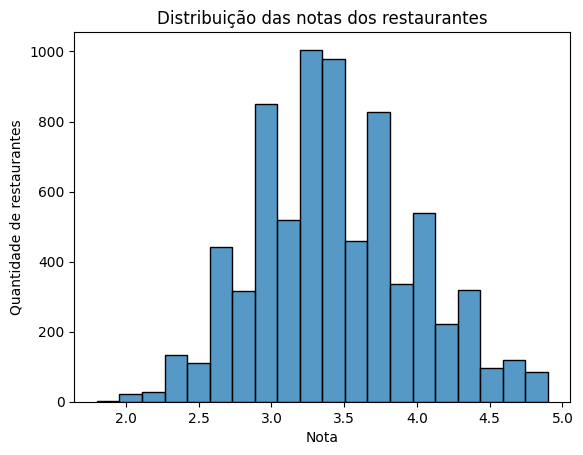

In [ ]:
sns.histplot(df_limpo['Aggregate rating'], bins=20)
plt.title("Distribuição das notas dos restaurantes")
plt.xlabel("Nota")
plt.ylabel("Quantidade de restaurantes")
plt.show()


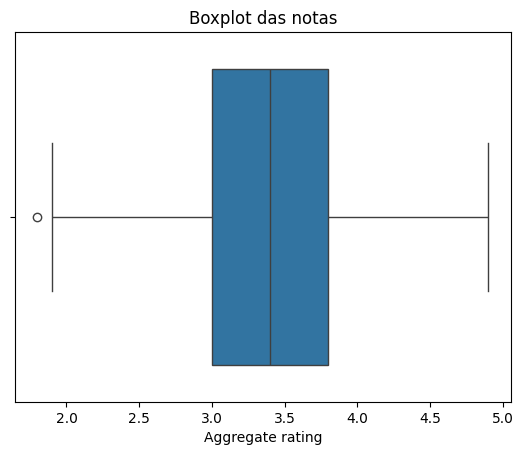

In [ ]:
sns.boxplot(x=df_limpo['Aggregate rating'])
plt.title("Boxplot das notas")
plt.show()

In [ ]:
df_limpo["Has Online delivery"].value_counts()

,count
Has Online delivery,
No,5048
Yes,2355


In [ ]:
df_limpo["Has Online delivery"].value_counts(normalize=True) * 100

,proportion
Has Online delivery,
No,68.188572
Yes,31.811428


Sem os restaurantes não avaliados, a média das notas (3,44) ficou igual à mediana (3,4), e a distribuição tem formato de sino, concentrada entre 3 e 4. Há só um outlier (nota 1,8), que mantive por ser um valor real. Dos 7.403 restaurantes, 5.048 não têm entrega online e 2.355 têm.

## Etapa 5: Comparar os grupos

Comparo a nota dos restaurantes com e sem entrega online.

In [ ]:
df_limpo.groupby("Has Online delivery")["Aggregate rating"].agg(["count","mean","median", "std"])

,count,mean,median,std
Has Online delivery,,,,
No,5048,3.467433,3.4,0.555283
Yes,2355,3.381274,3.4,0.540974


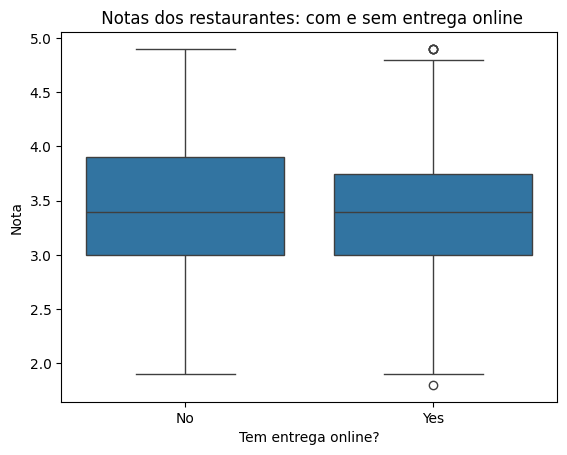

In [ ]:
sns.boxplot(data=df_limpo, x="Has Online delivery", y="Aggregate rating")
plt.title(" Notas dos restaurantes: com e sem entrega online")
plt.xlabel("Tem entrega online?")
plt.ylabel("Nota")
plt.show()

In [ ]:
medias = df_limpo.groupby("Has Online delivery")["Aggregate rating"].mean()
diferenca = medias["No"] - medias["Yes"]
print(f"Diferença entre as médias: {diferenca:.3f}")

Diferença entre as médias: 0.086


Restaurantes sem entrega online têm nota média de 3,47, contra 3,38 dos que têm entrega. As medianas são iguais (3,4) e os boxplots são parecidos. A diferença de média (0,086) é pequena, e preciso testar se ela é estatisticamente real.

## Etapa 6: Teste de hipótese

Testo se a diferença entre as notas médias dos dois grupos é estatisticamente real.

- **H0 (hipótese nula):** a nota média é igual nos dois grupos.
- **H1 (hipótese alternativa):** a nota média é diferente.

In [ ]:
from scipy import stats

com_entrega = df_limpo[df_limpo["Has Online delivery"] == "Yes"]["Aggregate rating"]
sem_entrega = df_limpo[df_limpo["Has Online delivery"] == "No"]["Aggregate rating"]

In [ ]:
t, p = stats.ttest_ind(sem_entrega, com_entrega, equal_var=False)

print(f"Estatística t: {t:.3f}")
print(f"p-valor: {p:.2e}")

Estatística t: 6.329
p-valor: 2.71e-10


In [ ]:
diferenca = sem_entrega.mean() - com_entrega.mean()
erro = np.sqrt(sem_entrega.var() / len(sem_entrega) + com_entrega.var() / len(com_entrega))

print(f"Diferença: {diferenca:.3f}")
print(f"Intervalo de confiança 95%: {diferenca - 1.96 * erro:.3f} a {diferenca + 1.96 * erro:.3f}")

Diferença: 0.086
Intervalo de confiança 95%: 0.059 a 0.113


In [ ]:
u, p_mw = stats.mannwhitneyu(sem_entrega, com_entrega, alternative="two-sided")
print(f"p-valor (Mann-Whitney): {p_mw:.4f}")

p-valor (Mann-Whitney): 0.0009


O teste t deu p-valor de aproximadamente 2,7e-10, e o Mann-Whitney confirmou (p ≈ 0,0009), então rejeito a hipótese nula: a diferença entre as médias é estatisticamente significativa. Restaurantes sem entrega têm nota média 0,086 maior (intervalo de confiança de 0,059 a 0,113). Porém o efeito é pequeno na prática.

## Etapa 7: Conclusão

/tmp/ipykernel_1074/3711784311.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Sem entrega online", "Com entrega online"])


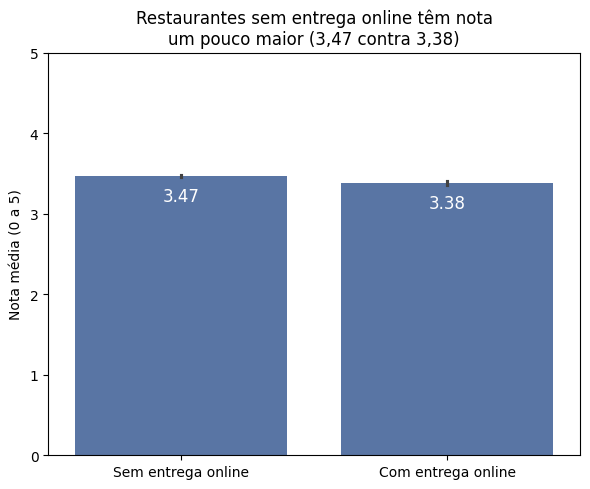

In [ ]:
plt.figure(figsize=(6, 5))
ax = sns.barplot(
    data=df_limpo,
    x="Has Online delivery",
    y="Aggregate rating",
    order=["No", "Yes"],
    errorbar=("ci", 95),
    color="#4C72B0",
)

ax.set_xticklabels(["Sem entrega online", "Com entrega online"])
ax.set_ylim(0, 5)
ax.set_xlabel("")
ax.set_ylabel("Nota média (0 a 5)")
ax.set_title("Restaurantes sem entrega online têm nota\num pouco maior (3,47 contra 3,38)")

for barra in ax.patches:
    ax.annotate(
        f"{barra.get_height():.2f}",
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, -18),
        textcoords="offset points",
        ha="center",
        color="white",
        fontsize=12,
    )

plt.tight_layout()
plt.savefig("grafico_final.png", dpi=150)
plt.show()

## Conclusão

**Resposta:** Sim, existe diferença. Restaurantes sem entrega online têm nota média de 3,47, contra 3,38 dos restaurantes com entrega, uma diferença de 0,086 pontos.

**Evidência:** O teste t (p ≈ 2,7e-10) e o Mann-Whitney (p ≈ 0,0009) indicam que a diferença é estatisticamente significativa. O intervalo de confiança de 95% da diferença vai de 0,059 a 0,113 pontos.

**Limites da análise:**
- A diferença é pequena na prática (efeito de cerca de 0,16, numa escala de 0 a 5).
- O resultado mostra uma associação, não prova que a entrega online causa a nota menor. Fatores como cidade, preço e tipo de cozinha não foram controlados.
- Removi os 2.148 restaurantes sem avaliação, então a conclusão vale só para restaurantes avaliados.
- A grande maioria dos dados é da Índia, então o resultado pode não valer para outros países.

**Próximos passos possíveis:** repetir a comparação separando por faixa de preço, por cidade ou por tipo de cozinha.